## Conceptual definition

**Ball Carrier Open Space (BCOS)** describes where the current carrier could
move with the ball before an opponent intervenes. For every hypothetical target
within 40m, PRESS estimates a carrier-arrival probability under competition with
defenders along that route. Integrating that field gives a probability-weighted
accessible **area in m²**. This is a current-state opportunity, not the area the
player will actually traverse or a prediction of the chosen route.

Bandara et al. introduce BCOS and analyse its spatial and temporal variation
[@bandara2025bcos]. Their construction uses event freeze frames and the visible
area. Here we use tracking positions, velocities and an arrival/competing-risk
model. This is a **PRESS formalization inspired by the concept**, not a
reproduction of their metric. We use it as a feature and descriptive statistic;
we do not fit a match-winner model on these ten games.

BCOS is an optional `PRESS.extras.BCOS` object. The
[action-selection vignette](../../04_action_selection/04_action_selection.ipynb)
explains why its scalar area is one of the classifier's inputs. A short-horizon
[carry-loss probability](../../01_ball_drive_risk/01_ball_drive_risk.ipynb)
and BCOS describe different quantities: one forecasts loss for a prescribed
one-second motion; the other evaluates routes to many alternative targets.

## Mathematical model

All calculations below condition on the observed state $s_0$: carrier and
defender positions/velocities and actual pitch dimensions. Teammates are shown
on the pitch but do not compete against their own carrier in this calculation.
The assumptions and the spatial marginalization below are **own derivation**.
Spearman motivates acceleration-limited arrival, logistic uncertainty and
competition for remaining probability mass [@spearman2017; @spearman2018beyond].

### 1. Targets, paths and motion

For carrier origin $r_B$, the target domain is

$$\mathcal D_{40}=\{z:\|z-r_B\|\le40\mathrm{m}\}\cap\mathrm{pitch}.$$

For each target $z$, construct a straight path $z_0=r_B,\ldots,z_M=z$.
The native target grid is1m; the much finer path spacing is approximately
0.03125m. The endpoint is retained by spacing the path evenly over its selected
number of intervals. These are two separate discretizations.

A player with current speed $u$ first incurs an effective turning delay
$t_{turn}=u\theta/a_{turn}$, then accelerates toward the point with linear
capacity $a$ up to speed $V$. With
$t_a=\max((V-u)/a,0)$ and $d_a=u t_a+\tfrac12 a t_a^2$:

$$t_{move}(d)=\begin{cases}
(\sqrt{u^2+2ad}-u)/a,&d\le d_a,\\
t_a+(d-d_a)/\max(u,V),&d>d_a.
\end{cases}$$

Thus $\tau_j(z_k)=t_{turn,j}(z_k)+t_{move,j}(z_k)$. An observed speed above
$V$ is retained without further acceleration. Distance at most0.1m gives
$\tau=0$. The turn is a fixed-position delay, with no explicit displacement
along the circular arc. Its directional-delay motivation follows the Pleuler/
Bekkers family; our centripetal scale and sequential routine are explicit
project assumptions [@pleuler2020handbook; @bekkers2025]. No reaction-time drift
or measured initial acceleration is added. The full shared routine is also
explained in the carry vignette.

### 2. Arrival gates and spatial carrier weights

Set $\alpha=\pi/(\sqrt3s)$ and

$$F_j(k,t)=\operatorname{sigmoid}\{\alpha[t-\tau_j(z_k)]\}.$$

For a single logistic arrival distribution, $f/(1-F)=\alpha F$ is its hazard.
Here $s$ is arrival-time dispersion in seconds, not a speed or tackle rate.

Approximate carrier location along the route using differences between
neighbouring arrival gates. Override the origin gate by
$\bar F_B(0,t)=1$; elsewhere $\bar F_B(k,t)=F_B(k,t)$. Then

$$w_k(t;z)=[\bar F_B(k,t)-\bar F_B(k+1,t)]_+,
\quad k=0,\ldots,M-1;\qquad w_M(t;z)=0.$$

At the initial integration step, all spatial weight is put at the origin.
The weights represent route intervals before the destination; they are not
renormalized to sum to one. With ordered gates their sum is $1-F_B(M,t)$.
The target-arrival hazard uses the original logistic gate, including at the
origin, not the overridden location-weight gate.

### 3. Intervention conditional on carrier location

At path point $z_k$, defender $i$ contributes the local opportunity rate
$\alpha F_i(k,t)$. Marginalize over the carrier's route weights:

$$h_i(t;z)=\sum_{k=0}^{M-1}w_k(t;z)\,\alpha F_i(k,t),
\qquad h_B(t;z)=\alpha F_B(M,t).$$

This defines the model's **conditional-hazard construction** while the route
experiment remains unresolved. It uses a working spatial representation from
arrival gates; it does not fit a separate tactical route-choice model.
**The product of a spatial weight and an arrival gate is not a time CDF.**
We do not differentiate that product to obtain an intervention-time density.
BCOS also does not reuse the learned carry tackle-rate spline: it borrows
the fitted arrival dispersion and the shared kinematics.

### 4. Shared survival and target probability

Let $U_z(t)$ be probability that neither carrier arrival nor intervention has
resolved the experiment for target $z$. Let $C_z$ be cumulative carrier
incidence and $D_{i,z}$ defender incidence. Define

$$\dot U_z=-U_z\left(h_B+\sum_i h_i\right),\qquad
\dot C_z=U_z h_B,\qquad \dot D_{i,z}=U_z h_i,$$

with $U_z(0)=1$ and all incidences initially zero. Therefore
$U_z+C_z+\sum_iD_{i,z}=1$. The map reports $p_B(z)=C_z(T)$, with a15s ceiling.

For rates frozen over a step $\Delta$, let $H=h_B+\sum_i h_i$ and
$M=U_z(1-e^{-H\Delta})$. Exponential Euler updates

$$U_z\leftarrow U_z e^{-H\Delta},\qquad
C_z\leftarrow C_z+M\,h_B/H,\qquad
D_{i,z}\leftarrow D_{i,z}+M\,h_i/H.$$

No mass is released when $H=0$. This preserves nonnegative probabilities and
their sum. A target can stop early once $U_z\le10^{-9}$: any additional carrier
incidence is bounded by that remaining mass.

### 5. Scalar area and interpretation

$$A_{BCOS}(s_0)=\int_{\mathcal D_{40}}p_B(z)\,dz
\ \approx\ \sum_{z\in\mathcal G}p_B(z)\,\Delta A,
\qquad \Delta A=(1\mathrm{m})^2.$$

Each target is an alternative hypothetical route. Its probability partition
sums to one, but probabilities across different targets need not. Consequently
BCOS is an **area**, not a probability of selecting one destination.

The area is naturally smaller where the pitch boundary removes possible
destinations. If expressing it as a fraction, use the fixed full-circle area
$\pi40^2$ as denominator; dividing by the clipped available domain would remove
that physical-space effect. The feature and figures below retain m².


## Parameters and numerical evidence

| Setting | Final value and justification |
|---|---|
| Defender speed | 7m/s, an effective engagement running scale supported by the moving-engager tracking tail. |
| Carrier speed | 6.6m/s. The approximate literature speed reduction with ball gives $7\times0.94=6.58$, rounded; jointly moving engagement Q95 values are6.778/7.174m/s, a5.52% difference. |
| Linear acceleration | 7m/s² for carrier and defenders, following Spearman's effective acceleration and checked against tracking upper tails. |
| Turning scale | 7m/s² for both, configurable separately; an effective simplification rather than a measured individual turning limit. |
| Dispersion | Installed carry fit: $s=0.299632$s. Fold-specific fits supply training/OOF feature stacks; the descriptive example uses production parameters throughout. |
| Domain and targets | Radius40m, clipped to actual pitch;1m target grid and1m² quadrature weights. |
| Path and time | Path spacing0.03125m; integration step0.04s; maximum15s; residual-mass stopping threshold$10^{-9}$. |

Speed categories, paired tracking populations and acceleration sensitivities
are documented in the [kinematic conventions](../../../docs/kinematic-parameter-conventions.md)
[@bradley2009running; @spearman2018beyond; @carling2010ballrunning; @benhassen2026dribbling].
The ball-running reduction does not establish a matching acceleration reduction;
we retain the stated7m/s² acceleration assumption. Tracking velocities use
centred seven-frame Savitzky–Golay derivatives at10Hz: this is offline smoothing
with three future frames of velocity support. No observed future route is used.

The40m domain defines a broad local metric. In5,963 matched positive-duration
outfield/no-shot individual possessions, observed radial excursion has
P95=17.736m and P99=28.193m;14 exceed40m. This contextualizes the radius, not an
assertion that longer carries are impossible. The hypothetical target routes
are not required to match the route the player actually chose.

At fixed40m and dt0.04s, the selected0.03125m path spacing passed all25
state/fold comparisons against two finer references,0.015625 and0.0078125m;
worst conservative area discrepancy was0.9651%. These are sampled numerical
checks, not a universal bound. The earlier0.0625m candidate failed9of25 checks.

Temporal sensitivity is a separate issue. In six varied cases, dt0.04 versus
0.01s changes area by at most0.262m². Refining two extremely close-defender
cases to0.0025s gives differences0.270 and0.331m², or3.92% and6.30% of small
areas. Thus the1% path result is **not** a1% guarantee on time discretization
or every cell probability. The final convention remains unchanged.

[Path checks](../../../data/examples/bcos/path_convergence.csv),
[time-step checks](../../../data/examples/bcos/temporal_convergence.csv),
[sensitive-case refinements](../../../data/examples/bcos/temporal_refinement.csv).


## BCOS as an input to action selection and residual risk

The fitted models actually use this area, rather than merely displaying it.
Categorical one-hot gains are grouped into conceptual features for the ranking.

| Model | BCOS rank in production refit | Share of total split gain | Rank across five outer folds |
|---|---:|---:|---:|
| Action selection | 5 | 4.10% | 4–7 |
| Residual risk | 1 | 14.21% | 1–4 |

Split gain attributes fitting-loss reduction to tree splits; these percentages
are not percentages of predictive accuracy or causal contribution. A separate
fixed-model OOF sensitivity permutes BCOS among test rows **within each match**,
with20seeds, leaving all other direct features fixed:

| Model | Native pooled CE | Mean CE after BCOS permutation | Relative CE increase |
|---|---:|---:|---:|
| Action selection,16,918 states | 0.568592 | 0.572385 | 0.67% |
| Residual risk,7,820 states | 0.419506 | 0.428644 | 2.18% |

For residual, recomputing the matching AS-derived P(carry) after the same
permutation gives CE0.428681, almost unchanged from the direct perturbation.
This is consistent with a stronger direct continuation-risk role than the
indirect action-propensity path. Correlation with other spatial/pressure inputs
means permutation may create unusual feature combinations; this is **not** a
causal effect, drop-feature refit, confidence interval or model-selection step.
No model or benchmark is replaced by this diagnostic.

[Split-gain tables](../../../data/examples/bcos/feature_split_gain.csv) ·
[OOF permutation summary](../../../data/examples/bcos/feature_permutation_summary.csv) ·
[all perturbation seeds](../../../data/examples/bcos/feature_permutation_by_seed.csv).



## Worked calculation on a real tracking frame

The case is **Brisbane FC–Perth Glory,21December2024**, match1925299.
We select frame15032, timestamp25:02.20, the first eligible production
checkpoint at or after minute25. Selection does not use outcome or BCOS value.
Brisbane's carrier is `home_17`, close to the attacking boundary.

With the full numerical convention, the public API evaluates1,721 targets and
returns **46.4451m²**. The maximum target partition error is$1.34\times10^{-15}$;
the largest remaining mass is below$10^{-9}$. The original production cache
contains46.4450726m²; using the raw processed frame differs by only
$9.1\times10^{-6}$m² because the cached state coordinates were stored in float32.

The following cell recomputes the real model if processed local inputs are
available. Set `PRESS_BCOS_MATCH_DIR` to the corresponding match directory.
Without private/local inputs, it shows the already computed real-case figure
and verified summary, rather than substituting a synthetic field. Source data:
SkillCorner Open Data [@skillcorner-opendata].


Actual carrier: home_17
BCOS area (m²): 46.44508164148423
Targets: 1721
Maximum probability-mass error: 1.3322676295501878e-15
Difference from the verified real-case export (m²): 0.0


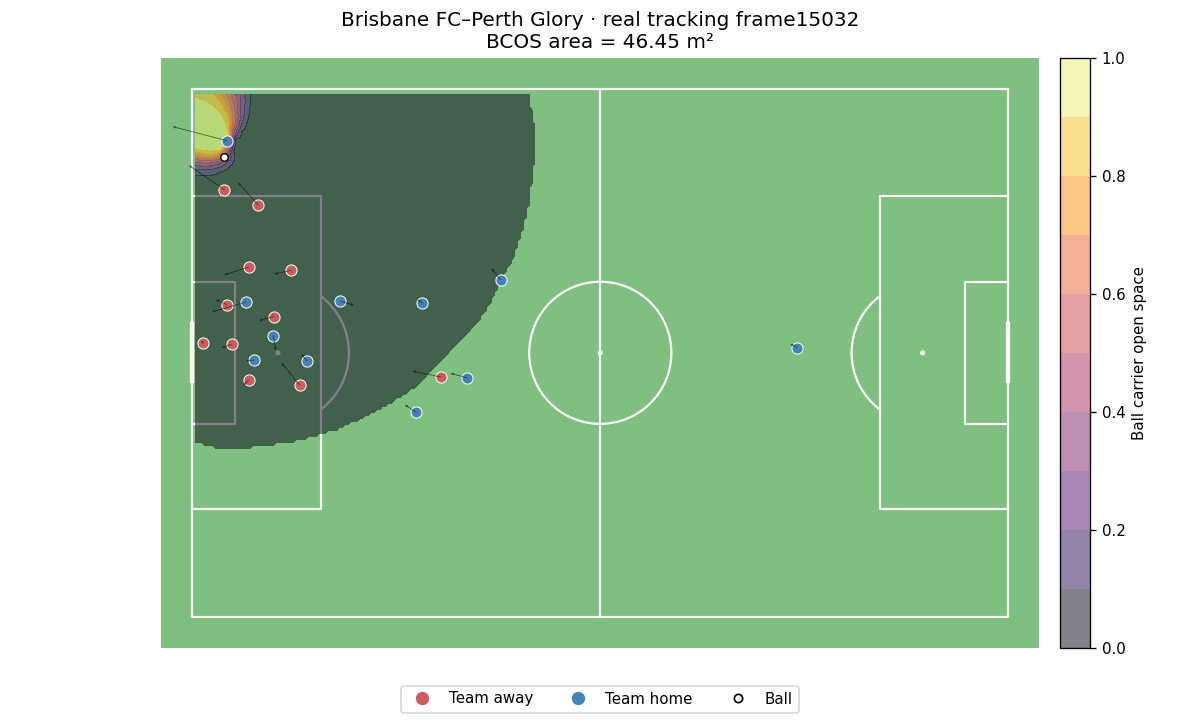

In [5]:
import os
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PRESS import PRESS
from PRESS.extras import BCOS
from PRESS.visualization import plot_bcos

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "_quarto.yml").is_file())
summary = json.loads((root / "data/examples/bcos/example_summary.json").read_text())
default_dir = root.parent / "opendata/data/processed/2026-10-15_training_v5_outfield/matches/1925299"
match_dir = Path(os.environ.get("PRESS_BCOS_MATCH_DIR", str(default_dir)))
frame_id = summary["frame_id"]
if (match_dir / "1925299_tracking.parquet").is_file():
    press = PRESS.from_skillcorner(match_dir)
    bcos = BCOS(press.tracking_data)
    result = bcos.compute_bcos(frame_id)  # full40m/1m/0.03125m/0.04s defaults
    print("Actual carrier:", press.get_state(frame_id)["player"] if "player" in press.get_state(frame_id) else summary["carrier_id"])
    print("BCOS area (m²):", result["BCOS area"])
    print("Targets:", len(result["grid"]))
    print("Maximum probability-mass error:", result["max_mass_error"])
    print("Difference from the verified real-case export (m²):", result["BCOS area"] - summary["bcos_area_m2"])
    assert np.isclose(result["BCOS area"], summary["bcos_area_m2"], rtol=0, atol=1e-6)
    plot_bcos(bcos, frame_id, figsize=(10, 6), title_fontsize=11, legend_fontsize=9)
    fig = plt.gcf()
    fig.axes[0].set_title("Brisbane FC–Perth Glory · real tracking frame15032\nBCOS area = %.2f m²" % result["BCOS area"])
else:
    print("Real-case local data unavailable: showing the verified rendered calculation.")
    print("BCOS area (m²):", summary["bcos_area_m2"])
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(plt.imread(root / "figures/vignette_10_bcos.png"))
    ax.axis("off")
    plt.tight_layout()


The field is a set of target-arrival probabilities. Dark locations inside the
40m domain have little modeled accessibility; locations outside that domain
are not evaluated. The boundary removes physically unavailable destinations.
The field follows the current carrier/defender configuration and shared motion
assumptions; it does not describe the observed future carry outcome.

## One-match spatial and temporal description

The same match supplies **1,928 verified production checkpoints** from931
individual possessions:1,238 checkpoints/592 possessions for Brisbane and
690/339 for Perth. These are the canonical outfield/no-shot action-choice
states, including pass releases and failed carries. They are **not all10Hz
frames, uniform time samples or a possession-time measure**. Within this predefined action-choice cohort, no extra outcome-based selection
is used to build the descriptive report.

Reuse the full-data production BCOS values for this descriptive report. The
OOF convention remains unchanged for predictive benchmarks. In this selected
sample Brisbane's mean/median area is311.42/101.99m²; Perth's is226.64/73.64m².
This describes available space at sampled states, not team quality or a
prediction of the eventual0–1 score.

### Spatial heatmap: BCOS where the carrier is

Orient both teams to attack right, including after half time. Divide the field
into an **8×5 display grid** (approximately13.1×13.6m cells), distinct from the
1m probability grid. For team $a$ and origin cell $g$,

$$\bar A_{a,g}=\frac1{n_{a,g}}\sum_{j:\,team_j=a,\,r_{B,j}\in g}A_{BCOS}(s_j).$$

Colour is this **checkpoint mean area**, not a sum, occupancy duration or
probability mass at the target cell. Labels report distinct individual
possessions. Both teams share the same scale. Cells with fewer than five
distinct possessions are hatched, with their values retained in the source
table; empty cells stay blank. Seven slightly outside-pitch carrier states
are outside this origin grid, without clipping or deletion from the model or
temporal summaries.

The resolution is a transparent display compromise. Compared6×4/8×5/10×6/
12×8/15×10: at8×5, the occupied-cell median has20distinct possessions for
Brisbane and10for Perth. Supported cells cover97.9%/93.6% of their in-pitch
checkpoints. Finer grids leave more weakly populated cells. Whole-team-possession
resampling and held-out spatial-mean checks support caution about fine detail;
they measure **aggregation stability**, not numerical or predictive error of
BCOS. No uniquely optimal grid or universal five-possession threshold is claimed.

![Colour: mean available BCOS at the carrier origin. Labels: distinct individual possessions; both teams attack right and share the colour scale.](../../../figures/bcos_match_spatial.png)

### Temporal curves by team and carrier third

Following Bandara's idea of examining defensive, central and attacking thirds,
use five equal windows in each half, giving ten temporal windows overall
[@bandara2025bcos]. Here a third refers to the **carrier's current position**.
For window $b$ and third $q$:

$$\bar A_{a,q,b}=\frac1{n_{a,q,b}}\sum_{j:\,team_j=a,\,r_{B,j}\in q,\,t_j\in b}A_{BCOS}(s_j).$$

Each curve shows the mean complete40m-domain BCOS conditional on that origin
third. It does not partition the target probability field into thirds.
Means use available checkpoints; no interpolation across empty/unsupported
windows or halftime and no substitution of missing values by zero. Means
with fewer than five individual possessions are left as gaps. Halves have
separate axes in minutes elapsed within that half, preserving added time.

![Mean BCOS by carrier third and squad, with separate halves and five windows per half.](../../../figures/bcos_match_temporal.png)

### What is visible in this match sample

| Carrier third | Brisbane mean BCOS (m²) | Perth mean BCOS (m²) |
|---|---:|---:|
| Defensive | 548.31 | 277.33 |
| Central | 365.72 | 260.13 |
| Attacking | 81.64 | 68.23 |

The largest descriptive difference is in the defensive third, followed by the
centre. Available area is much smaller in the attacking third for both teams,
where pressure geometry and pitch-boundary constraints both matter. These
aggregates do not separate those mechanisms or establish tactical causality.
Brisbane's larger overall mean therefore does not imply a comparable advantage
near goal, nor does it predict the final0–1 result.

Means exceed medians substantially: a subset of very open states contributes
to the averages. The spatial table also provides medians. In Perth's attacking
third during the second half, only the first window has five or more individual
possessions; the later curve is intentionally left incomplete. Missing points
mean insufficient sampled support, not zero open space.

Bandara's event-based area/visible-area/time aggregation differs from these
checkpoint means. The visual organization is inspired by that work; the
estimand, tracking inputs and units are explicitly our own. Event frequency,
situation mix, missing tracking and repeated states affect these summaries.
We make no claim that these curves predict the winner or establish causality.

### Reading the match: opportunities, territory and score context

The spatial and temporal views together suggest **Brisbane had greater freedom
to build than to operate near the opposing goal**. Its largest mean areas lie
in the defensive third and the defensive-to-central corridor. The gap to Perth
is much smaller in the attacking third (81.6vs68.2m²). This is consistent with
space being available early in progression and becoming compressed closer to
goal; it does not establish which team movement caused or conceded that space.

The first half is not uniformly one-sided. Perth's early central mean exceeds
Brisbane's, but its median is smaller (112.7vs219.7m² in the first window),
so the mean alone would overstate routine freedom. Brisbane has a more evident
central-space advantage toward the end of that half. Neither team sustains a
clear large advantage in the supported attacking-third windows before halftime.

In the middle of the second half, Brisbane's defensive-third mean rises to
773–816m², with medians681–808m²: this is not solely one extreme open state.
Perth has much less sampled freedom in its own defensive third in those
windows (means56–135m²). A plausible tactical interpretation is Brisbane
facing less pressure during early construction while Perth encounters a more
restrictive configuration when starting its own possessions. BCOS alone does
not identify a pressing scheme, defensive line height or formation.

Perth scores at **68:25**, marked by the dotted orange line. Brisbane's large
rearward space is already present before that goal, so the score cannot be its
sole explanation. Toward the end, Brisbane has116attacking-third checkpoints
from45individual possessions in the final window, compared with Perth's6from3.
This is compatible with Brisbane pushing forward while Perth has fewer
represented attacking episodes after taking the lead. It is not a possession-
time or territory statistic, because the canonical sampling is not uniform.
Perth's late attacking curve is left incomplete rather than assigning it zero.

The useful football reading is therefore **more available construction space
for Brisbane, much less separation between the teams near goal, and a late
shift in sampled attacking presence toward Brisbane**. Treat this as a match
profile and hypotheses to inspect in video or additional tactical summaries,
not an established habitual team style or a causal space-creation attribution.
The unchanged0–1 outcome also illustrates why open area and chance quality
should not be treated as interchangeable quantities.

[Phase summaries around the goal](../../../data/examples/bcos/match_phase_summary.csv).

### Inspect and reproduce the descriptive figures

The public files contain aggregates only. Rebuild these plots with
`python scripts/build_bcos_vignette_figures.py`. Model recomputation requires
local processed tracking. The analysis scripts and source hashes are recorded
in the [vignette provenance](../../../docs/bcos-vignette-provenance.json).


In [7]:
import pandas as pd
from scripts.build_bcos_vignette_figures import main as rebuild_bcos_figures
rebuild_bcos_figures()
print(pd.read_csv(root / "data/examples/bcos/team_summary.csv").to_string(index=False))
print("Spatial and temporal cell definitions:")
print(json.loads((root / "data/examples/bcos/metadata.json").read_text())["sampling"])


BCOS_DESCRIPTIVE_FIGURES_REBUILT
team   team_name  n_checkpoints  n_possessions  mean_bcos_m2  median_bcos_m2
away Perth Glory            690            339    226.637529       73.639882
home Brisbane FC           1238            592    311.424082      101.985800
Spatial and temporal cell definitions:
Exact1928canonical AS73 training-cohort checkpoints; not uniform10Hz, all-match time or a time-weighted estimate.


## Scope and references

BCOS depends on effective average motion, the straight-route assumption,
uncertain arrival gates and the conditional-hazard closure. It does not observe
body posture, ball-control skill, a player's chosen route or coordinated tactical
responses. The15s ceiling involves more extrapolation than a one-second carry
forecast. The probability field is a model-based opportunity, not an observed
ground truth. Spatial/time summaries remain descriptive on a selected match
sample; changing display bins does not change the model.

* Concept and temporal regional analysis: Bandara et al. [@bandara2025bcos].
* Arrival and control framework: Spearman [@spearman2017; @spearman2018beyond].
* Direction-sensitive reachability motivation: Pleuler and Bekkers
  [@pleuler2020handbook; @bekkers2025]; the acceleration/turning parameterization
  and BCOS spatial marginalization above are project derivations.
* Movement-scale context: Bradley, Carling and Benhassen et al.
  [@bradley2009running; @carling2010ballrunning; @benhassen2026dribbling].
* Tracking data: SkillCorner Open Data [@skillcorner-opendata].

[Aggregate data and definitions](../../../data/examples/bcos/README.md) ·
[grid support](../../../data/examples/bcos/grid_support.csv) ·
[spatial cells, medians and bootstrap spread](../../../data/examples/bcos/spatial_cells.csv) ·
[temporal windows and counts](../../../data/examples/bcos/temporal_thirds.csv).
